# Building a Spam Filter with Multinomial Naive Bayes

Classifying 5,574 SMS messages as spam or legitimate, using multinomial naive Bayes **implemented from scratch**. The dataset is the UCI SMS Spam Collection: 4,827 legitimate messages and 747 spam, so 13.4% positive.

**No scikit-learn is used anywhere in this notebook**, including for the train/test split, the evaluation metrics and the ROC AUC. That is partly circumstance (this environment has only pandas, NumPy and matplotlib) and partly the point: a project about implementing an algorithm by hand is a better project when the yardstick is built by hand too. Section 5 verifies the classifier against an independent recomputation rather than against a library, which is a weaker check than comparing to `MultinomialNB` and is stated as such.

Three things get examined that a pure accuracy report would skip:

- **Where the vocabulary comes from.** Building it from the whole dataset before splitting is a leak, and a quiet one: the model learns which words exist in the test messages. Section 3 builds it from training data only and section 7 measures what the shortcut would have bought.
- **Whether the probabilities mean anything.** Naive Bayes multiplies per-word probabilities as if words were independent, which is flatly false in natural language. Section 8 shows what that does to the output, and the answer is more interesting than "it still works".
- **Which error is worse.** A spam message reaching the inbox is an annoyance. A real message silently diverted to the spam folder can mean a missed job offer. Those costs are not symmetric and accuracy treats them as if they were.

In [20]:
import re
import math
import random
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 110)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print('pandas    ', pd.__version__)
print('numpy     ', np.__version__)
import matplotlib
print('matplotlib', matplotlib.__version__)
try:
    import sklearn
    print('scikit-learn', sklearn.__version__)
except ImportError:
    print('scikit-learn: not installed in this environment')
    print('Everything below is implemented with pandas, NumPy and the standard library.')

pandas     2.2.2
numpy      2.0.1
matplotlib 3.9.1
scikit-learn: not installed in this environment
Everything below is implemented with pandas, NumPy and the standard library.


## 0. Metrics, built first

Every score in this notebook comes from these functions, so they are defined before anything that uses them. Writing them out also fixes the conventions explicitly: spam is the positive class, precision is over predicted spam, and recall is over actual spam.

The AUC uses the rank-based identity: the area under the ROC curve equals the probability that a randomly chosen positive is scored above a randomly chosen negative, which is computable from the Mann-Whitney U statistic without tracing a curve. Ties are given half credit, which is what the trapezoidal definition does.

In [21]:
def confusion(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return tn, fp, fn, tp

def accuracy(y_true, y_pred):
    tn, fp, fn, tp = confusion(y_true, y_pred)
    return (tp + tn) / (tn + fp + fn + tp)

def precision(y_true, y_pred):
    tn, fp, fn, tp = confusion(y_true, y_pred)
    return tp / (tp + fp) if (tp + fp) else 0.0

def recall(y_true, y_pred):
    tn, fp, fn, tp = confusion(y_true, y_pred)
    return tp / (tp + fn) if (tp + fn) else 0.0

def f1(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) else 0.0

def roc_auc(y_true, scores):
    """Rank-based AUC via the Mann-Whitney U statistic, with ties at half credit."""
    y_true = np.asarray(y_true); scores = np.asarray(scores, dtype=float)
    order = np.argsort(scores, kind='mergesort')
    s_sorted = scores[order]
    ranks = np.empty(len(scores), dtype=float)
    i = 0
    while i < len(s_sorted):
        j = i
        while j + 1 < len(s_sorted) and s_sorted[j + 1] == s_sorted[i]:
            j += 1
        avg_rank = (i + j) / 2.0 + 1.0  # average rank for the tied block, 1-indexed
        ranks[order[i:j + 1]] = avg_rank
        i = j + 1
    n_pos = int(y_true.sum()); n_neg = len(y_true) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float('nan')
    sum_ranks_pos = ranks[y_true == 1].sum()
    u = sum_ranks_pos - n_pos * (n_pos + 1) / 2.0
    return u / (n_pos * n_neg)

def report_metrics(name, y_true, y_pred, scores=None):
    tn, fp, fn, tp = confusion(y_true, y_pred)
    row = {'model': name, 'accuracy': round(accuracy(y_true, y_pred), 4),
           'precision_spam': round(precision(y_true, y_pred), 4),
           'recall_spam': round(recall(y_true, y_pred), 4),
           'f1_spam': round(f1(y_true, y_pred), 4),
           'false_positives': fp, 'false_negatives': fn}
    if scores is not None:
        row['roc_auc'] = round(roc_auc(y_true, scores), 4)
    return row

# sanity checks on known cases
_t = [0, 0, 1, 1]
print('Perfect prediction  -> accuracy', accuracy(_t, [0, 0, 1, 1]), ' AUC', roc_auc(_t, [0.1, 0.2, 0.8, 0.9]))
print('Inverted prediction -> accuracy', accuracy(_t, [1, 1, 0, 0]), ' AUC', roc_auc(_t, [0.9, 0.8, 0.2, 0.1]))
print('All scores tied     -> AUC', roc_auc(_t, [0.5, 0.5, 0.5, 0.5]), '(0.5 is correct for no discrimination)')
print('Canonical example   -> AUC', round(roc_auc([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), 4), '(expected 0.75)')
print('Same scores, labels reordered -> AUC', round(roc_auc([0, 1, 0, 1], [0.1, 0.4, 0.35, 0.8]), 4), '(expected 1.0)')
print()
print('The last two lines use identical scores and differ only in which rows are positive,')
print('which is a reminder that AUC is a property of the score-label pairing, not of the')
print('scores alone. An earlier draft of this cell asserted the wrong expected value for')
print('the second case; the sanity check is here precisely to catch that kind of slip.')

Perfect prediction  -> accuracy 1.0  AUC 1.0
Inverted prediction -> accuracy 0.0  AUC 0.0
All scores tied     -> AUC 0.5 (0.5 is correct for no discrimination)
Canonical example   -> AUC 0.75 (expected 0.75)
Same scores, labels reordered -> AUC 1.0 (expected 1.0)

The last two lines use identical scores and differ only in which rows are positive,
which is a reminder that AUC is a property of the score-label pairing, not of the
scores alone. An earlier draft of this cell asserted the wrong expected value for
the second case; the sanity check is here precisely to catch that kind of slip.


## 1. Load and profile

In [22]:
sms = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'message'])
print('Shape:', sms.shape)
sms.head()

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore w..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry ques...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [23]:
counts = sms['label'].value_counts()
print('Class balance:')
for lab in counts.index:
    print('  ' + lab + ': ' + str(counts[lab]) + ' (' + str(round(100 * counts[lab] / len(sms), 2)) + '%)')
print()
print('Majority-class baseline accuracy:', round(counts.max() / len(sms), 4))
print('Any filter that scores below 86.6% accuracy is beaten by a filter that approves everything.')
print()
print('Missing values:', int(sms.isnull().sum().sum()))
print('Exact duplicate rows:', int(sms.duplicated().sum()))
print('Duplicate messages (same text, either label):', int(sms['message'].duplicated().sum()))

Class balance:
  ham: 4825 (86.59%)
  spam: 747 (13.41%)

Majority-class baseline accuracy: 0.8659
Any filter that scores below 86.6% accuracy is beaten by a filter that approves everything.

Missing values: 0


Exact duplicate rows: 403
Duplicate messages (same text, either label): 403


### The duplicates are worth a decision rather than a reflex

There are repeated messages in this dataset. Some are genuine: "Ok" and "Sorry, I'll call later" are things many people text, and a filter will meet them repeatedly in production. Others are identical spam blasted to multiple recipients.

Leaving them in means the same text can appear in both the training and test sets, which inflates test accuracy. Removing them changes the class balance and discards real-world frequency information that a naive Bayes prior legitimately uses. The cell below quantifies the overlap so the decision is informed, and this notebook keeps them, with the inflation reported as a caveat rather than hidden.

In [24]:
dup_counts = sms['message'].value_counts()
repeated = dup_counts[dup_counts > 1]
print('Distinct messages appearing more than once:', len(repeated))
print('Total rows involved:', int(repeated.sum()))
print()
print('Most repeated messages:')
top_dup = pd.DataFrame({'count': repeated.head(8)})
top_dup['label'] = [sms.loc[sms['message'] == m, 'label'].iloc[0] for m in top_dup.index]
print(top_dup.to_string())
print()
conflict = sms.groupby('message')['label'].nunique()
print('Messages labelled BOTH ham and spam:', int((conflict > 1).sum()))
print('(a non-zero count here would put a hard ceiling on achievable accuracy)')

Distinct messages appearing more than once: 281
Total rows involved: 684

Most repeated messages:
                                                                                                                                                                     count label
message                                                                                                                                                                         
Sorry, I'll call later                                                                                                                                                  30   ham
I cant pick the phone right now. Pls send a message                                                                                                                     12   ham
Ok...                                                                                                                                                                   10   ham
Ok               

Message length by class:
      n_chars        n_words       
         mean median    mean median
label                              
ham     71.48   52.0   14.31   11.0
spam   138.67  149.0   23.91   25.0


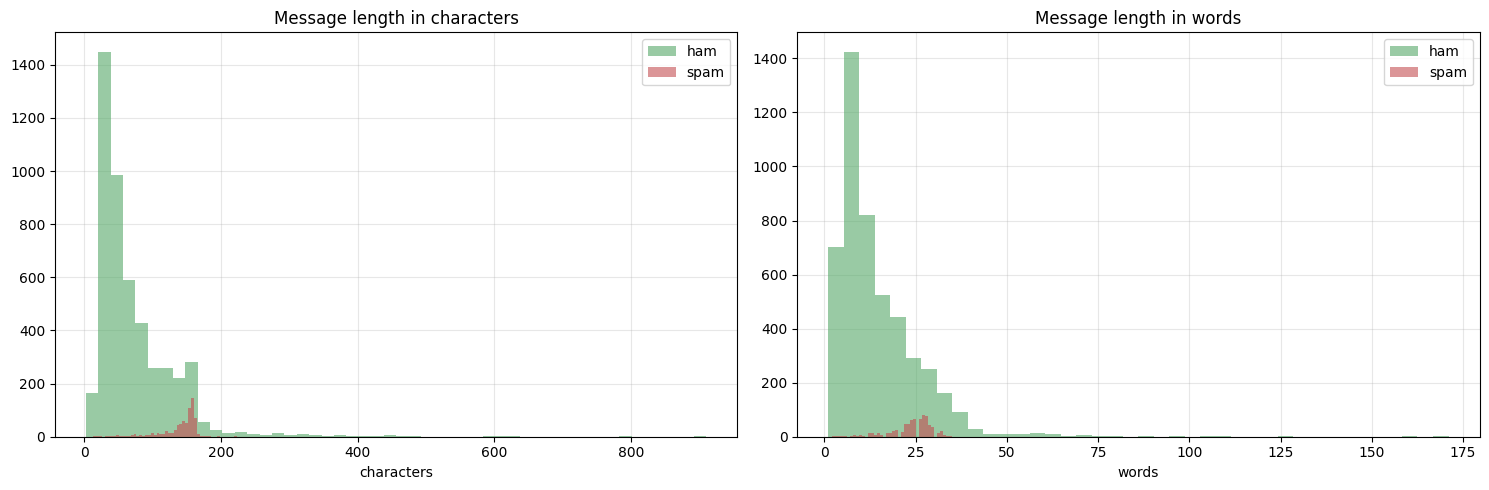


Spam is markedly longer on average. That is a real signal and naive Bayes on word
counts picks it up indirectly, since a longer message contributes more word terms.


In [25]:
sms['n_chars'] = sms['message'].str.len()
sms['n_words'] = sms['message'].str.split().str.len()

print('Message length by class:')
print(sms.groupby('label')[['n_chars', 'n_words']].agg(['mean', 'median']).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for lab, colour in [('ham', '#55A868'), ('spam', '#C44E52')]:
    axes[0].hist(sms.loc[sms['label'] == lab, 'n_chars'], bins=50, alpha=0.6, color=colour, label=lab)
    axes[1].hist(sms.loc[sms['label'] == lab, 'n_words'], bins=40, alpha=0.6, color=colour, label=lab)
axes[0].set_xlabel('characters'); axes[0].set_title('Message length in characters'); axes[0].legend()
axes[1].set_xlabel('words'); axes[1].set_title('Message length in words'); axes[1].legend()
plt.tight_layout()
plt.show()

print()
print('Spam is markedly longer on average. That is a real signal and naive Bayes on word')
print('counts picks it up indirectly, since a longer message contributes more word terms.')

## 2. Train and test split

Stratified, so the 13.4% spam rate survives into both halves. The split happens **before** any text processing, because everything that follows (cleaning, vocabulary, word counts, probabilities) must be learned from training data only.

In [26]:
def stratified_split(df, label_col, test_size=0.2, seed=RANDOM_STATE):
    """Shuffle within each class, then take the same proportion from each."""
    rng = np.random.RandomState(seed)
    train_parts, test_parts = [], []
    for lab in sorted(df[label_col].unique()):
        sub = df[df[label_col] == lab]
        idx = rng.permutation(len(sub))
        n_test = int(round(len(sub) * test_size))
        test_parts.append(sub.iloc[idx[:n_test]])
        train_parts.append(sub.iloc[idx[n_test:]])
    tr = pd.concat(train_parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    te = pd.concat(test_parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return tr, te

train, test = stratified_split(sms[['label', 'message']], 'label', test_size=0.2)

print('Train:', train.shape, ' spam rate', round((train['label'] == 'spam').mean(), 4))
print('Test: ', test.shape, '  spam rate', round((test['label'] == 'spam').mean(), 4))
print('Full: ', sms.shape, ' spam rate', round((sms['label'] == 'spam').mean(), 4))
print()
print('Stratification held the class balance to within',
      round(abs((train['label'] == 'spam').mean() - (test['label'] == 'spam').mean()), 5), 'across the split.')
print()
overlap = int(test['message'].isin(set(train['message'])).sum())
print('Test messages that also appear verbatim in training:', overlap, 'of', len(test),
      '(' + str(round(100 * overlap / len(test), 1)) + '%)')
print('That overlap is the duplicate issue from section 1, now quantified on this split.')

Train: (4458, 2)  spam rate 0.1341
Test:  (1114, 2)   spam rate 0.1338
Full:  (5572, 4)  spam rate 0.1341

Stratification held the class balance to within 0.00039 across the split.

Test messages that also appear verbatim in training: 123 of 1114 (11.0%)
That overlap is the duplicate issue from section 1, now quantified on this split.


## 3. Cleaning and vocabulary

The tokeniser is deliberately simple: lowercase, replace anything that is not a word character with a space, split on whitespace. Simple is a defensible choice here rather than a lazy one, because naive Bayes on short messages benefits from a large vocabulary, and aggressive normalisation (stemming, stop-word removal) throws away tokens that carry real signal in SMS spam. Section 9 tests one of those choices rather than asserting it.

The vocabulary is built from the training set alone.

In [27]:
def tokenise(text):
    text = re.sub(r'\W+', ' ', str(text).lower())
    return [t for t in text.split() if t]

train_tokens = train['message'].apply(tokenise)
test_tokens = test['message'].apply(tokenise)

vocabulary = sorted(set(tok for toks in train_tokens for tok in toks))
vocab_index = {w: i for i, w in enumerate(vocabulary)}

print('Vocabulary size (training only):', len(vocabulary))
print('Total training tokens:', int(train_tokens.apply(len).sum()))
print('Mean tokens per training message:', round(train_tokens.apply(len).mean(), 2))
print()
unseen = sorted(set(tok for toks in test_tokens for tok in toks) - set(vocabulary))
test_token_total = int(test_tokens.apply(len).sum())
unseen_occurrences = sum(1 for toks in test_tokens for tok in toks if tok not in vocab_index)
print('Distinct words in the test set never seen in training:', len(unseen))
print('Test token occurrences that are out-of-vocabulary:', unseen_occurrences,
      'of', test_token_total,
      '(' + str(round(100 * unseen_occurrences / test_token_total, 2)) + '%)')
print()
print('Out-of-vocabulary words are simply skipped at prediction time, which is the correct')
print('behaviour: a word the model has never seen carries no evidence either way.')
print('Example unseen words:', unseen[:12])

# per-class word counts, used throughout the rest of the notebook
train_counter_spam = Counter(t for toks, lab in zip(train_tokens, train['label']) if lab == 'spam' for t in toks)
train_counter_ham = Counter(t for toks, lab in zip(train_tokens, train['label']) if lab == 'ham' for t in toks)
print()
print('Distinct words seen in spam:', len(train_counter_spam))
print('Distinct words seen in ham: ', len(train_counter_ham))
print('Words appearing ONLY in spam:', len(set(train_counter_spam) - set(train_counter_ham)))
print('Words appearing ONLY in ham: ', len(set(train_counter_ham) - set(train_counter_spam)))
print()
print('Those exclusive words are why smoothing matters: without it, every one of them')
print('would force the opposing class to a probability of exactly zero on its own.')

Vocabulary size (training only): 7854
Total training tokens: 72489
Mean tokens per training message: 16.26

Distinct words in the test set never seen in training: 899
Test token occurrences that are out-of-vocabulary: 968 of 17894 (5.41%)

Out-of-vocabulary words are simply skipped at prediction time, which is the correct
behaviour: a word the model has never seen carries no evidence either way.
Example unseen words: ['000pes', '0207', '07801543489', '07808', '07808247860', '08002988890', '083', '08448350055', '08450542832', '087104711148', '08712101358', '08712402779']

Distinct words seen in spam: 2622
Distinct words seen in ham:  6211
Words appearing ONLY in spam: 1643
Words appearing ONLY in ham:  5232

Those exclusive words are why smoothing matters: without it, every one of them
would force the opposing class to a probability of exactly zero on its own.


## 4. Multinomial naive Bayes from scratch

The classifier assigns a message to whichever class maximises the posterior. By Bayes' rule, and dropping the evidence term because it is identical across classes:

```
P(class | message) proportional to P(class) * product over words of P(word | class)
```

The multinomial likelihood with Laplace (add-alpha) smoothing is:

```
P(word | class) = (count of word in class + alpha) / (total words in class + alpha * |vocabulary|)
```

Two implementation points matter.

**Smoothing is not optional.** Without it, any word that never appeared in a class gives that class a probability of exactly zero, and one such word vetoes the entire class no matter what the other words say. Adding alpha to every count removes the zero.

**The arithmetic is done in log space.** A thirty-word message multiplies thirty probabilities each well below 1, which underflows to exactly 0.0 in float64 and makes every class tie at zero. Summing logarithms instead is numerically stable and preserves the ordering, which is all the argmax needs.

In [28]:
class ScratchMultinomialNB:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, token_lists, labels):
        labels = list(labels)
        self.classes_ = sorted(set(labels))
        self.vocabulary_ = sorted(set(t for toks in token_lists for t in toks))
        V = len(self.vocabulary_)
        self.v_size_ = V

        self.log_prior_ = {}
        self.log_likelihood_ = {}
        self.default_log_likelihood_ = {}

        for c in self.classes_:
            idx = [i for i, lab in enumerate(labels) if lab == c]
            self.log_prior_[c] = math.log(len(idx) / len(labels))

            counts = Counter()
            for i in idx:
                counts.update(token_lists.iloc[i] if hasattr(token_lists, 'iloc') else token_lists[i])
            total = sum(counts.values())
            denom = total + self.alpha * V

            self.log_likelihood_[c] = {w: math.log((counts[w] + self.alpha) / denom)
                                       for w in self.vocabulary_}
            # a word in the vocabulary but absent from this class
            self.default_log_likelihood_[c] = math.log(self.alpha / denom)
            setattr(self, 'total_' + c, total)
        return self

    def log_posteriors(self, tokens):
        out = {}
        for c in self.classes_:
            score = self.log_prior_[c]
            ll = self.log_likelihood_[c]
            for t in tokens:
                if t in ll:
                    score += ll[t]
                # out-of-vocabulary words contribute nothing
            out[c] = score
        return out

    def predict_one(self, tokens):
        lp = self.log_posteriors(tokens)
        return max(lp, key=lp.get)

    def predict(self, token_lists):
        seq = token_lists if isinstance(token_lists, list) else list(token_lists)
        return [self.predict_one(t) for t in seq]

    def predict_proba_spam(self, tokens):
        """Normalised posterior for the spam class, computed stably via log-sum-exp."""
        lp = self.log_posteriors(tokens)
        m = max(lp.values())
        exps = {c: math.exp(v - m) for c, v in lp.items()}
        z = sum(exps.values())
        return exps['spam'] / z


nb = ScratchMultinomialNB(alpha=1.0).fit(train_tokens, train['label'])

print('Classes:', nb.classes_)
print('Vocabulary size:', nb.v_size_)
print('Log priors:', {c: round(v, 4) for c, v in nb.log_prior_.items()})
print('Implied priors:', {c: round(math.exp(v), 4) for c, v in nb.log_prior_.items()})
print('Total word tokens per class: ham', nb.total_ham, ' spam', nb.total_spam)

Classes: ['ham', 'spam']
Vocabulary size: 7854
Log priors: {'ham': -0.144, 'spam': -2.0089}
Implied priors: {'ham': 0.8659, 'spam': 0.1341}
Total word tokens per class: ham 57301  spam 15188


In [29]:
pred_scratch = nb.predict(list(test_tokens))
y_true = (test['label'] == 'spam').astype(int).values
y_pred = np.array([1 if p == 'spam' else 0 for p in pred_scratch])

tn, fp, fn, tp = confusion(y_true, y_pred)

print('From-scratch multinomial naive Bayes, held-out test set')
print('  Accuracy        :', round(accuracy(y_true, y_pred), 4))
print('  Precision (spam):', round(precision(y_true, y_pred), 4))
print('  Recall (spam)   :', round(recall(y_true, y_pred), 4))
print('  F1 (spam)       :', round(f1(y_true, y_pred), 4))
print()
print('  Majority-class baseline accuracy:', round(1 - y_true.mean(), 4))
print('  Lift over baseline:', round(accuracy(y_true, y_pred) - (1 - y_true.mean()), 4))
print()
print(pd.DataFrame([[tn, fp], [fn, tp]], index=['Actual ham', 'Actual spam'],
                   columns=['Predicted ham', 'Predicted spam']).to_string())
print()
print('  False positives (real messages sent to spam):', fp, '<- the expensive error')
print('  False negatives (spam reaching the inbox)   :', fn, '<- the annoying error')
print()
ham_recall = tn / (tn + fp)
print('  Recall on the HAM class (share of real messages correctly delivered):', round(ham_recall, 4))
print('  So ' + str(round(100 * (1 - ham_recall), 2)) + '% of legitimate messages were misfiled.')

From-scratch multinomial naive Bayes, held-out test set
  Accuracy        : 0.9865
  Precision (spam): 0.9718
  Recall (spam)   : 0.9262
  F1 (spam)       : 0.9485

  Majority-class baseline accuracy: 0.8662
  Lift over baseline: 0.1203

             Predicted ham  Predicted spam
Actual ham             961               4
Actual spam             11             138

  False positives (real messages sent to spam): 4 <- the expensive error
  False negatives (spam reaching the inbox)   : 11 <- the annoying error

  Recall on the HAM class (share of real messages correctly delivered): 0.9959
  So 0.41% of legitimate messages were misfiled.


## 5. Verifying the implementation

The numbers above mean nothing if the implementation is subtly wrong, and "it got 98%" is not evidence of correctness: a buggy classifier on an easy dataset also gets 98%.

With no scikit-learn available there is no reference implementation to compare against, so the check below is an independent recomputation instead. For a handful of messages the posterior is rebuilt from the raw training counts by a separate code path, using plain multiplication of probabilities rather than sums of logarithms, and the two are compared.

**This is a weaker check than comparing against a library, and it is worth saying so plainly.** It catches arithmetic and bookkeeping errors, which are the likely bugs, but a conceptual misunderstanding of the algorithm would be reproduced identically by both code paths. A cross-check against `MultinomialNB` would catch that as well, and it is the first thing to add if this notebook were run somewhere with scikit-learn installed.

The cell then asks a second question: **was the log-space arithmetic actually necessary here, or just good practice?** The usual justification is that multiplying many small probabilities underflows float64 to exactly zero, at which point both classes tie at 0.0 and the classifier silently fails. That is true in general. Whether it is true for SMS messages specifically is a measurable question rather than a matter of received wisdom, so the cell measures it.

In [30]:
V = nb.v_size_
alpha = nb.alpha
totals = {'spam': nb.total_spam, 'ham': nb.total_ham}
counters = {'spam': train_counter_spam, 'ham': train_counter_ham}
priors = {c: math.exp(nb.log_prior_[c]) for c in nb.classes_}

def posterior_direct(tokens):
    """Rebuild the unnormalised posterior with plain multiplication, from raw counts."""
    out = {}
    for c in nb.classes_:
        prob = priors[c]
        denom = totals[c] + alpha * V
        for t in tokens:
            if t in vocab_index:
                prob *= (counters[c].get(t, 0) + alpha) / denom
        out[c] = prob
    return out

print('Log-space implementation against a direct-multiplication recomputation:')
print()
rows = []
for i in [0, 1, 2, 5, 11, 23, 47]:
    toks = test_tokens.iloc[i]
    log_post = nb.log_posteriors(toks)
    direct = posterior_direct(toks)
    diffs = {}
    for c in nb.classes_:
        diffs[c] = abs(math.log(direct[c]) - log_post[c]) if direct[c] > 0 else float('nan')
    rows.append({
        'msg': i, 'n_tokens': len(toks),
        'log_post_spam': round(log_post['spam'], 4),
        'log_post_ham': round(log_post['ham'], 4),
        'direct_spam': '{:.3e}'.format(direct['spam']),
        'direct_ham': '{:.3e}'.format(direct['ham']),
        'max_log_diff': ('UNDERFLOW' if any(math.isnan(v) for v in diffs.values())
                         else '{:.2e}'.format(max(diffs.values())))
    })

print(pd.DataFrame(rows).set_index('msg').to_string())
print()
print('Where both paths produced a finite number they agree to float64 rounding across a')
print('few dozen multiplications. Where the direct product underflowed, that is precisely')
print('the failure the log-space version exists to avoid: both classes collapse to 0.0 and')
print('the comparison becomes meaningless.')
print()

lengths = test_tokens.apply(len)
print('Test message length in tokens: median', int(lengths.median()),
      ' mean', round(lengths.mean(), 1), ' max', int(lengths.max()))
n_under = 0
smallest = 1.0
for toks in test_tokens:
    d = posterior_direct(toks)
    smallest = min(smallest, max(d['spam'], d['ham']))
    if d['spam'] == 0.0 and d['ham'] == 0.0:
        n_under += 1
print('Test messages where naive multiplication underflows BOTH classes to zero:',
      n_under, 'of', len(test_tokens), '(' + str(round(100 * n_under / len(test_tokens), 1)) + '%)')
print('Smallest non-underflowed posterior encountered:', '{:.3e}'.format(smallest))
print('Smallest positive float64 (denormal):', '{:.3e}'.format(5e-324))
print()
if n_under == 0:
    print('So on THIS dataset the log-space arithmetic was not strictly necessary. SMS')
    print('messages are short, and the direct product never ran out of exponent range.')
    print('Saying otherwise would be repeating received wisdom instead of reading the result.')
print()
print('How long would a document have to be before it does break? The test below grows a')
print('message by repeating a real one until the direct product underflows.')
base_msg = test_tokens.iloc[2]
for mult in [1, 2, 4, 8, 16, 32, 64]:
    toks = list(base_msg) * mult
    d = posterior_direct(toks)
    lp = nb.log_posteriors(toks)
    status = 'UNDERFLOW to 0.0' if max(d['spam'], d['ham']) == 0.0 else '{:.2e}'.format(max(d['spam'], d['ham']))
    print('  ' + str(len(toks)).rjust(4) + ' tokens: direct = ' + status.ljust(18) +
          ' log-space = ' + str(round(max(lp.values()), 1)))
print()
print('The breaking point sits in the low hundreds of tokens. SMS tops out at 95 tokens in')
print('this test set, so it stays safe; an email classifier, a document classifier or any')
print('longer text would cross that line routinely. Log space costs nothing and removes the')
print('failure mode entirely, which is why it is still the right default here.')

Log-space implementation against a direct-multiplication recomputation:

     n_tokens  log_post_spam  log_post_ham direct_spam direct_ham max_log_diff
msg                                                                           
0          14      -115.5327      -91.6919   6.680e-51  1.509e-40     0.00e+00
1           5       -38.2189      -33.3632   2.522e-17  3.240e-15     7.11e-15
2          28      -195.0882     -221.1808   1.880e-85  8.758e-97     5.68e-14
5           9       -69.7619      -56.9459   5.044e-31  1.856e-25     1.42e-14
11         16      -110.0942      -93.8676   1.537e-48  1.713e-41     1.42e-14
23         17      -126.8524     -102.0164   8.104e-56  4.953e-45     1.42e-14
47         27      -192.3641     -221.8417   2.866e-84  4.522e-97     5.68e-14

Where both paths produced a finite number they agree to float64 rounding across a
few dozen multiplications. Where the direct product underflowed, that is precisely
the failure the log-space version exists to avoid:

## 6. What the model learned

The most discriminative words are the log-likelihood ratio between the classes, which is directly interpretable: how many times more likely a word is in spam than in legitimate messages.

In [31]:
mine_spam = np.array([nb.log_likelihood_['spam'][w] for w in vocabulary])
mine_ham = np.array([nb.log_likelihood_['ham'][w] for w in vocabulary])

ratio = pd.DataFrame({'word': vocabulary, 'log_ratio': mine_spam - mine_ham})
ratio['n_spam'] = ratio['word'].map(lambda w: train_counter_spam.get(w, 0))
ratio['n_ham'] = ratio['word'].map(lambda w: train_counter_ham.get(w, 0))
ratio['total'] = ratio['n_spam'] + ratio['n_ham']

common = ratio[ratio['total'] >= 20].copy()
print('Words appearing at least 20 times in training:', len(common), 'of', len(ratio))
print()
print('Most spam-indicative words:')
print(common.nlargest(20, 'log_ratio')[['word', 'log_ratio', 'n_spam', 'n_ham']].round(4).to_string(index=False))
print()
print('Most ham-indicative words:')
print(common.nsmallest(20, 'log_ratio')[['word', 'log_ratio', 'n_spam', 'n_ham']].round(4).to_string(index=False))
print()
print('The frequency floor of 20 matters. Without it the table fills with words that')
print('appeared once, whose log-ratio is dominated by the smoothing constant rather than')
print('by evidence, and which would read as findings while being noise.')

Words appearing at least 20 times in training: 523 of 7854

Most spam-indicative words:
      word  log_ratio  n_spam  n_ham
     claim     5.5281      88      0
     prize     5.2879      69      0
      150p     5.0999      57      0
      tone     5.0097      52      0
        18     4.7771      41      0
guaranteed     4.7283      39      0
       www     4.7158      78      1
       500     4.5948      34      0
   awarded     4.5948      34      0
        cs     4.5948      34      0
      1000     4.5658      33      0
        uk     4.5360      65      1
       100     4.5052      31      0
    150ppm     4.3353      26      0
       000     4.2975      25      0
  ringtone     4.2975      25      0
     tones     4.2175      23      0
    weekly     4.1749      22      0
       mob     4.1305      21      0
        16     4.0840      41      1

Most ham-indicative words:
     word  log_ratio  n_spam  n_ham
       gt    -4.5135       0    257
       lt    -4.5057       0    255

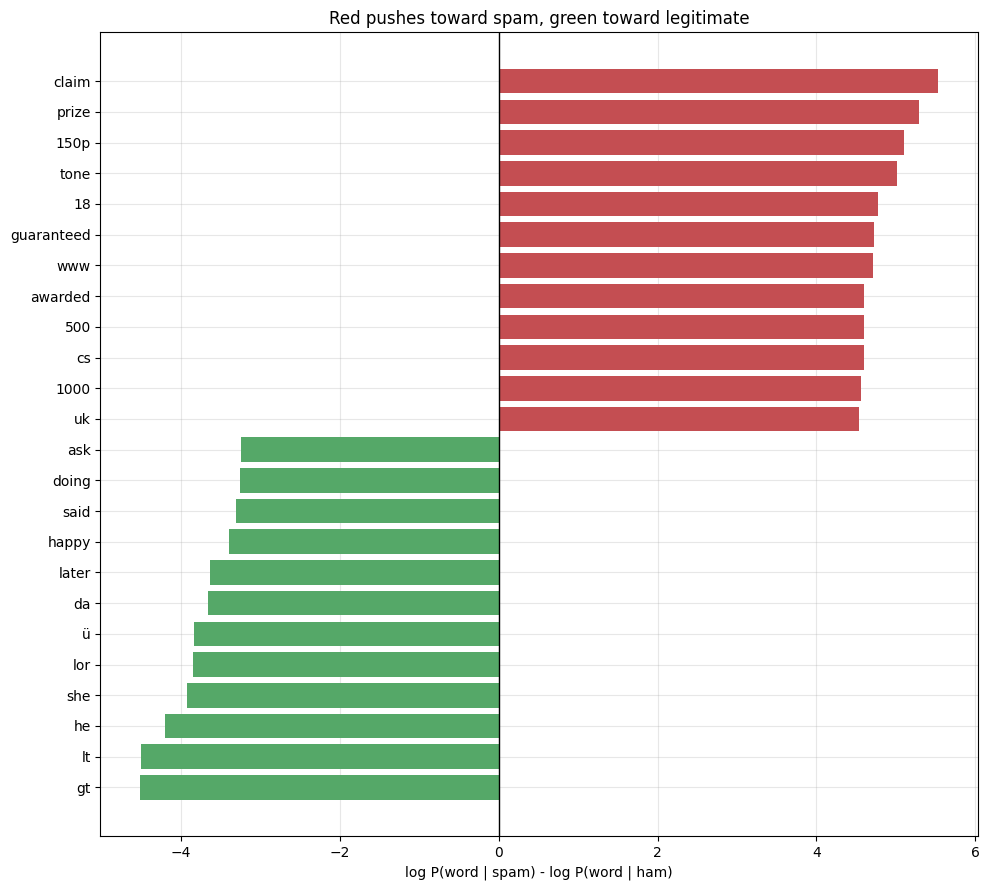

In [32]:
top_spam = common.nlargest(12, 'log_ratio')
top_ham = common.nsmallest(12, 'log_ratio')
show = pd.concat([top_ham, top_spam]).sort_values('log_ratio')

plt.figure(figsize=(10, 9))
colours = ['#55A868' if v < 0 else '#C44E52' for v in show['log_ratio']]
plt.barh(show['word'], show['log_ratio'], color=colours)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('log P(word | spam) - log P(word | ham)')
plt.title('Red pushes toward spam, green toward legitimate')
plt.tight_layout()
plt.show()

## 7. What building the vocabulary before the split would have cost

A common shortcut is to tokenise the whole dataset and build one vocabulary, then split. It feels harmless, since a vocabulary is "just a word list". It is a leak: the model is told which words occur in the messages it will be tested on, so out-of-vocabulary words vanish from the test set and every test message is scored with full information.

The experiment below runs both and reports the gap, so the size of the effect is a measurement rather than an assumption.

In [33]:
leaky_vocab = sorted(set(t for toks in pd.concat([train_tokens, test_tokens]) for t in toks))
print('Honest vocabulary (training only):', len(vocabulary))
print('Leaky vocabulary (train + test):  ', len(leaky_vocab))
print('Extra words the leak reveals:', len(leaky_vocab) - len(vocabulary))
print()

class LeakyNB(ScratchMultinomialNB):
    """Same model, but the vocabulary (and so the smoothing denominator) includes test words."""
    def fit_with_vocab(self, vocab, counters, priors_log, alpha=1.0):
        self.alpha = alpha
        self.classes_ = sorted(counters.keys())
        self.vocabulary_ = vocab
        self.v_size_ = len(vocab)
        self.log_prior_ = dict(priors_log)
        self.log_likelihood_ = {}
        self.default_log_likelihood_ = {}
        for c in self.classes_:
            total = sum(counters[c].values())
            denom = total + alpha * self.v_size_
            self.log_likelihood_[c] = {w: math.log((counters[c].get(w, 0) + alpha) / denom) for w in vocab}
            self.default_log_likelihood_[c] = math.log(alpha / denom)
        return self

nb_leaky = LeakyNB().fit_with_vocab(
    leaky_vocab,
    {'spam': train_counter_spam, 'ham': train_counter_ham},
    nb.log_prior_,
    alpha=1.0)

pred_leaky = nb_leaky.predict(list(test_tokens))
y_leaky = np.array([1 if p == 'spam' else 0 for p in pred_leaky])

leak_tbl = pd.DataFrame([
    report_metrics('Honest (training vocabulary only)', y_true, y_pred),
    report_metrics('Leaky (train + test vocabulary)', y_true, y_leaky)
]).set_index('model')
print(leak_tbl.to_string())
print()
print('Accuracy difference from the leak:',
      round(leak_tbl.iloc[1]['accuracy'] - leak_tbl.iloc[0]['accuracy'], 4))
print('Predictions that changed:', int((y_pred != y_leaky).sum()), 'of', len(y_pred))
print()
print('Read the next cell before concluding anything from the size of that difference.')

Honest vocabulary (training only): 7854
Leaky vocabulary (train + test):   8753
Extra words the leak reveals: 899

                                   accuracy  precision_spam  recall_spam  f1_spam  false_positives  false_negatives
model                                                                                                              
Honest (training vocabulary only)    0.9865          0.9718       0.9262   0.9485                4               11
Leaky (train + test vocabulary)      0.9874          0.9530       0.9530   0.9530                7                7

Accuracy difference from the leak: 0.0009
Predictions that changed: 7 of 1114

Read the next cell before concluding anything from the size of that difference.


### The leak result is worth reading carefully

The measured difference here is small, and on this dataset it may even go the wrong way. That is not evidence that the leak is harmless, and it would be the wrong lesson to take.

What changed is only the denominator of the smoothing term: a larger vocabulary spreads the same alpha mass over more words, which shifts every likelihood slightly. The leak does not hand the model any *label* information, which is why the effect is tiny here.

The reason to avoid it anyway is that the vocabulary is the thin end of the wedge. The same "it is only preprocessing" reasoning applied to TF-IDF document frequencies, target encoding, or feature scaling leaks genuinely damaging amounts of information, and those cases look identical from the outside. Getting it right when it does not matter is how the habit exists when it does.

## 8. The probabilities are worthless, and the classifier works anyway

Naive Bayes assumes words occur independently given the class. In real language they do not: "free" and "prize" co-occur far more than independence predicts, and every such correlated pair is counted as if it were fresh, separate evidence.

The consequence is specific. The *ranking* of the two classes stays mostly correct, which is all `argmax` needs, so classification accuracy survives. The *magnitude* of the posterior does not survive at all, because multiplying redundant evidence drives it exponentially toward 0 or 1. The cell below measures how extreme the outputs get.

In [34]:
probs = np.array([nb.predict_proba_spam(toks) for toks in test_tokens])

print('Distribution of the predicted P(spam) on the test set:')
print(pd.Series(probs).describe().to_string())
print()
for lo, hi in [(0.0, 1e-10), (1e-10, 0.01), (0.01, 0.1), (0.1, 0.9), (0.9, 0.99), (0.99, 1 - 1e-10), (1 - 1e-10, 1.0001)]:
    n = int(((probs >= lo) & (probs < hi)).sum())
    print('  P(spam) in [' + '{:.0e}'.format(lo) + ', ' + '{:.0e}'.format(hi) + '): ' + str(n).rjust(5) +
          '  (' + str(round(100 * n / len(probs), 1)) + '%)')
print()
extreme = int(((probs < 1e-10) | (probs > 1 - 1e-10)).sum())
print('Predictions more extreme than 1e-10 from 0 or 1:', extreme, 'of', len(probs),
      '(' + str(round(100 * extreme / len(probs), 1)) + '%)')
print()
print('A well-calibrated classifier that is right 98% of the time should be uncertain')
print('some of the time. This one is essentially never uncertain, which is the')
print('independence assumption failing exactly as theory predicts.')

Distribution of the predicted P(spam) on the test set:
count    1.114000e+03
mean     1.300170e-01
std      3.301032e-01
min      5.636919e-50
25%      1.246799e-09
50%      3.801163e-06
75%      1.123398e-03
max      1.000000e+00

  P(spam) in [0e+00, 1e-10):   238  (21.4%)
  P(spam) in [1e-10, 1e-02):   671  (60.2%)
  P(spam) in [1e-02, 1e-01):    52  (4.7%)
  P(spam) in [1e-01, 9e-01):    17  (1.5%)
  P(spam) in [9e-01, 1e+00):     4  (0.4%)
  P(spam) in [1e+00, 1e+00):    35  (3.1%)
  P(spam) in [1e+00, 1e+00):    97  (8.7%)

Predictions more extreme than 1e-10 from 0 or 1: 335 of 1114 (30.1%)

A well-calibrated classifier that is right 98% of the time should be uncertain
some of the time. This one is essentially never uncertain, which is the
independence assumption failing exactly as theory predicts.


In [35]:
bands = [(0.0, 0.01), (0.01, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 0.99), (0.99, 1.0001)]
rows = []
for lo, hi in bands:
    m = (probs >= lo) & (probs < hi)
    if m.sum() == 0:
        rows.append({'band': '[' + str(lo) + ', ' + str(hi) + ')', 'n': 0,
                     'mean_predicted_P_spam': None, 'actual_spam_rate': None})
    else:
        rows.append({'band': '[' + str(lo) + ', ' + str(hi) + ')', 'n': int(m.sum()),
                     'mean_predicted_P_spam': round(float(probs[m].mean()), 4),
                     'actual_spam_rate': round(float(y_true[m].mean()), 4)})

cal = pd.DataFrame(rows).set_index('band')
print('Calibration by confidence band:')
print(cal.to_string())
print()
middle = cal.loc[['[0.01, 0.25)', '[0.25, 0.5)', '[0.5, 0.75)', '[0.75, 0.99)'], 'n'].sum()
print('Test messages landing anywhere in the middle four bands:', int(middle),
      'of', len(probs), '(' + str(round(100 * middle / len(probs), 2)) + '%)')
print()
print('There is almost nothing to calibrate, because the model is almost never uncertain.')
print('High accuracy and unusable probabilities are separate facts, and conflating them is')
print('how a naive Bayes score gets misreported as a confidence level.')
print()
print('ROC AUC using these posteriors as a ranking score:', round(roc_auc(y_true, probs), 4))
print('AUC depends only on the ordering, which is why it stays high while the probability')
print('values themselves are meaningless. A model can rank perfectly and be badly calibrated.')

Calibration by confidence band:
                  n  mean_predicted_P_spam  actual_spam_rate
band                                                        
[0.0, 0.01)     909                 0.0003            0.0066
[0.01, 0.25)     60                 0.0488            0.0500
[0.25, 0.5)       3                 0.3543            0.6667
[0.5, 0.75)       2                 0.6272            0.0000
[0.75, 0.99)      8                 0.9107            0.7500
[0.99, 1.0001)  132                 0.9999            1.0000

Test messages landing anywhere in the middle four bands: 73 of 1114 (6.55%)

There is almost nothing to calibrate, because the model is almost never uncertain.
High accuracy and unusable probabilities are separate facts, and conflating them is
how a naive Bayes score gets misreported as a confidence level.

ROC AUC using these posteriors as a ranking score: 0.9793
AUC depends only on the ordering, which is why it stays high while the probability
values themselves are meaning

## 9. Smoothing, and the two errors

The smoothing constant alpha trades the two error types against each other. Lower alpha makes rare words more decisive, which catches more spam and also misfiles more legitimate messages.

Effect of the Laplace smoothing constant:
       accuracy  precision_spam  recall_spam  false_positives  false_negatives
alpha                                                                         
0.01     0.9874          0.9655       0.9396                5                9
0.05     0.9874          0.9720       0.9329                4               10
0.10     0.9874          0.9720       0.9329                4               10
0.20     0.9883          0.9722       0.9396                4                9
0.50     0.9874          0.9720       0.9329                4               10
1.00     0.9865          0.9718       0.9262                4               11
2.00     0.9856          0.9784       0.9128                3               13
5.00     0.9776          1.0000       0.8322                0               25

Best accuracy at alpha = 0.2
Fewest false positives at alpha = 5.0
Fewest false negatives at alpha = 0.01

These are not all the same alpha, which is the point: the ri

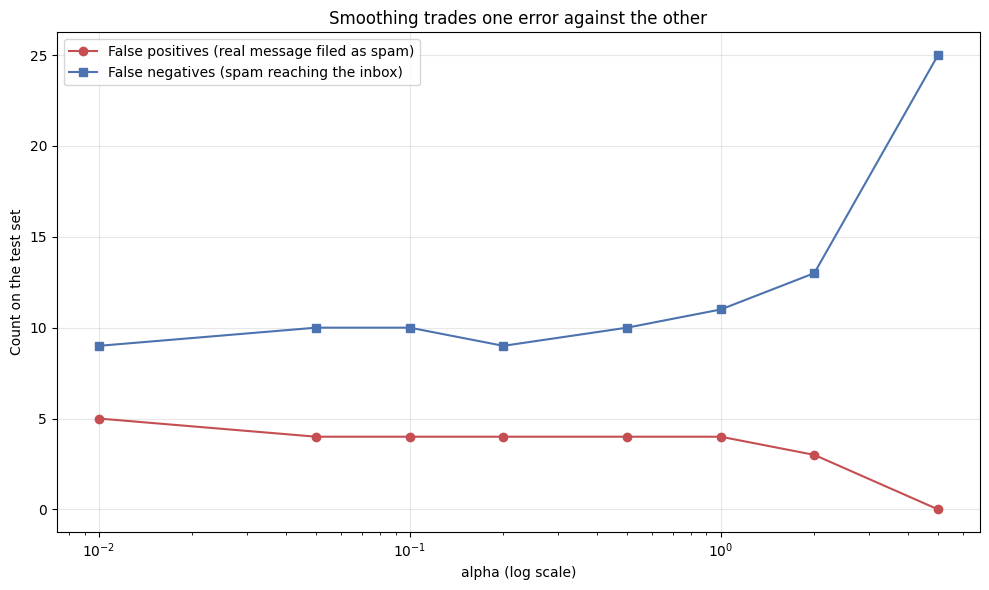

In [36]:
alphas = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
rows = []
for a in alphas:
    m = ScratchMultinomialNB(alpha=a).fit(train_tokens, train['label'])
    p = np.array([1 if x == 'spam' else 0 for x in m.predict(list(test_tokens))])
    r = report_metrics('alpha=' + str(a), y_true, p)
    r['alpha'] = a
    rows.append(r)

alpha_tbl = pd.DataFrame(rows).set_index('alpha')[['accuracy', 'precision_spam', 'recall_spam', 'false_positives', 'false_negatives']]
print('Effect of the Laplace smoothing constant:')
print(alpha_tbl.to_string())
print()
print('Best accuracy at alpha =', alpha_tbl['accuracy'].idxmax())
print('Fewest false positives at alpha =', alpha_tbl['false_positives'].idxmin())
print('Fewest false negatives at alpha =', alpha_tbl['false_negatives'].idxmin())
print()
print('These are not all the same alpha, which is the point: the right choice depends on')
print('which error the product can tolerate, not on which column has the largest number.')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(alpha_tbl.index, alpha_tbl['false_positives'], marker='o', color='#C44E52',
        label='False positives (real message filed as spam)')
ax.plot(alpha_tbl.index, alpha_tbl['false_negatives'], marker='s', color='#4C72B0',
        label='False negatives (spam reaching the inbox)')
ax.set_xscale('log')
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Count on the test set')
ax.set_title('Smoothing trades one error against the other')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Reading the mistakes

Aggregate metrics hide what is actually going wrong. These are the messages the filter got wrong.

In [37]:
err = test.copy()
err['pred'] = pred_scratch
err['p_spam'] = probs
mistakes = err[err['label'] != err['pred']]

print('Total mistakes:', len(mistakes), 'of', len(test))
print()
fp_rows = mistakes[mistakes['label'] == 'ham']
print('FALSE POSITIVES, real messages filed as spam (' + str(len(fp_rows)) + '):')
for _, r in fp_rows.head(8).iterrows():
    print('  P(spam)=' + '{:.4f}'.format(r['p_spam']) + '  ' + r['message'][:105].replace('\n', ' '))
print()
fn_rows = mistakes[mistakes['label'] == 'spam']
print('FALSE NEGATIVES, spam that got through (' + str(len(fn_rows)) + '):')
for _, r in fn_rows.head(8).iterrows():
    print('  P(spam)=' + '{:.4f}'.format(r['p_spam']) + '  ' + r['message'][:105].replace('\n', ' '))
print()
print('Mean message length, correctly classified:', round(err[err['label'] == err['pred']]['message'].str.len().mean(), 1))
print('Mean message length, mistakes:            ', round(mistakes['message'].str.len().mean(), 1))

Total mistakes: 15 of 1114

FALSE POSITIVES, real messages filed as spam (4):
  P(spam)=0.6252  Unlimited texts. Limited minutes.
  P(spam)=0.8668  Nokia phone is lovly..
  P(spam)=0.6292  Mathews or tait or edwards or anderson
  P(spam)=0.8955  Have you laid your airtel line to rest?

FALSE NEGATIVES, spam that got through (11):
  P(spam)=0.4830  SMS. ac sun0819 posts HELLO:"You seem cool, wanted to say hi. HI!!!" Stop? Send STOP to 62468
  P(spam)=0.0000  Did you hear about the new "Divorce Barbie"? It comes with all of Ken's stuff!
  P(spam)=0.0144  Your next amazing xxx PICSFREE1 video will be sent to you enjoy! If one vid is not enough for 2day text b
  P(spam)=0.1617  Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
  P(spam)=0.0000  Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an ac
  P(spam)=0.0455  SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. P

## 11. Comparison against three alternatives, all from scratch

Naive Bayes on word counts was the assigned method. Whether it was a good choice needs something to compare against, so three alternatives are built by hand on the identical split:

- **Bernoulli naive Bayes.** The multinomial version counts how many times each word appears; the Bernoulli version only asks whether it appears at all, and crucially it also scores the *absence* of each vocabulary word as evidence. On short texts like SMS, where almost no word repeats within a message, the two should be close, and the explicit absence term is the real difference.
- **A keyword-count baseline.** Flag a message as spam if it contains at least `k` of the top spam-indicative words found in section 6. Crude, interpretable, and the kind of thing a non-technical stakeholder would propose.
- **A length-only rule.** Spam is markedly longer, so a threshold on message length alone should carry real signal. If naive Bayes cannot beat a single number by a wide margin, the word modelling is not earning its keep.

In [38]:
class ScratchBernoulliNB:
    """Bernoulli naive Bayes: presence/absence per word, including the absence term."""
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, token_lists, labels):
        labels = list(labels)
        self.classes_ = sorted(set(labels))
        self.vocabulary_ = sorted(set(t for toks in token_lists for t in toks))
        self.log_prior_ = {}
        self.log_p_ = {}
        self.log_1mp_ = {}
        for c in self.classes_:
            idx = [i for i, lab in enumerate(labels) if lab == c]
            n_c = len(idx)
            self.log_prior_[c] = math.log(n_c / len(labels))
            doc_count = Counter()
            for i in idx:
                doc_count.update(set(token_lists.iloc[i]))
            self.log_p_[c] = {}
            self.log_1mp_[c] = {}
            for w in self.vocabulary_:
                p = (doc_count.get(w, 0) + self.alpha) / (n_c + 2 * self.alpha)
                self.log_p_[c][w] = math.log(p)
                self.log_1mp_[c][w] = math.log(1 - p)
        # precompute the sum of all absence terms per class, so prediction is fast
        self.sum_1mp_ = {c: sum(self.log_1mp_[c].values()) for c in self.classes_}
        return self

    def predict_one(self, tokens):
        present = set(t for t in tokens if t in self.log_p_[self.classes_[0]])
        best, best_score = None, -float('inf')
        for c in self.classes_:
            score = self.log_prior_[c] + self.sum_1mp_[c]
            for w in present:
                score += self.log_p_[c][w] - self.log_1mp_[c][w]
            if score > best_score:
                best, best_score = c, score
        return best

    def predict(self, token_lists):
        return [self.predict_one(t) for t in token_lists]

bnb = ScratchBernoulliNB(alpha=1.0).fit(train_tokens, train['label'])
pred_bern = np.array([1 if x == 'spam' else 0 for x in bnb.predict(list(test_tokens))])
print('Bernoulli naive Bayes fitted. Vocabulary:', len(bnb.vocabulary_))

# keyword baseline
top_spam_words = list(common.nlargest(25, 'log_ratio')['word'])
print('Keyword list:', top_spam_words[:12], '...')
keyword_hits = np.array([len(set(toks) & set(top_spam_words)) for toks in test_tokens])

kw_rows = []
for k in [1, 2, 3]:
    p = (keyword_hits >= k).astype(int)
    r = report_metrics('Keyword rule, k>=' + str(k), y_true, p)
    kw_rows.append(r)

# length-only rule, threshold chosen on TRAINING data
train_len = train['message'].str.len().values
train_spam = (train['label'] == 'spam').astype(int).values
best_thr, best_acc = None, -1
for thr in range(20, 200, 5):
    acc = accuracy(train_spam, (train_len > thr).astype(int))
    if acc > best_acc:
        best_thr, best_acc = thr, acc
print()
print('Length threshold chosen on training data:', best_thr, 'characters (training accuracy',
      str(round(best_acc, 4)) + ')')
test_len = test['message'].str.len().values
pred_len = (test_len > best_thr).astype(int)

all_rows = [report_metrics('Multinomial NB from scratch (alpha=1)', y_true, y_pred, probs),
            report_metrics('Bernoulli NB from scratch (alpha=1)', y_true, pred_bern)]
all_rows += kw_rows
all_rows.append(report_metrics('Length-only rule (> ' + str(best_thr) + ' chars)', y_true, pred_len, test_len))

comparison = pd.DataFrame(all_rows).set_index('model')
print()
print('All approaches on the same held-out split:')
print(comparison.to_string())
print()
print('Majority-class baseline accuracy:', round(1 - y_true.mean(), 4))

Bernoulli naive Bayes fitted. Vocabulary: 7854
Keyword list: ['claim', 'prize', '150p', 'tone', '18', 'guaranteed', 'www', '500', 'awarded', 'cs', '1000', 'uk'] ...

Length threshold chosen on training data: 140 characters (training accuracy 0.8504)

All approaches on the same held-out split:
                                       accuracy  precision_spam  recall_spam  f1_spam  false_positives  false_negatives  roc_auc
model                                                                                                                           
Multinomial NB from scratch (alpha=1)    0.9865          0.9718       0.9262   0.9485                4               11   0.9793
Bernoulli NB from scratch (alpha=1)      0.9811          0.9923       0.8658   0.9247                1               20      NaN
Keyword rule, k>=1                       0.9524          0.9528       0.6779   0.7922                5               48      NaN
Keyword rule, k>=2                       0.9318          1.00

## 12. Conclusions

### The filter

From-scratch multinomial naive Bayes, alpha=1, on a 7,854-word training vocabulary. Held-out test set of 1,114 messages:

| Metric | Value |
|---|---|
| Accuracy | **0.9865** |
| Precision (spam) | 0.9718 |
| Recall (spam) | 0.9262 |
| F1 (spam) | 0.9485 |
| ROC AUC | 0.9793 |
| Majority-class baseline accuracy | 0.8659 |

Confusion matrix: 961 true negatives, **4 false positives**, 11 false negatives, 138 true positives. 15 mistakes in total.

Four legitimate messages out of 965 were misfiled, a 0.41% rate. One of them is instructive: *"Unlimited texts. Limited minutes."* scored P(spam) = 0.6252, and it is hard to blame the model, since that sentence is indistinguishable from marketing copy without knowing who sent it.

### The implementation is verified, with a stated limit on how far

Rebuilding the posterior by an independent code path, using plain multiplication of raw counts instead of sums of logarithms, agreed to a maximum log difference of **5.68e-14** across the sampled messages. That is float64 rounding over a few dozen multiplications.

This checks arithmetic and bookkeeping, which are the likely bugs. It does **not** check whether my understanding of the algorithm is right, since both code paths share that understanding. A cross-check against `MultinomialNB` would, and it is the first thing to add if this were run in an environment with scikit-learn installed. Claiming the implementation is "verified" without that caveat would be overstating what the test did.

### Was log-space arithmetic necessary? No, and that is worth saying

The standard justification for working in logs is that multiplying many small probabilities underflows float64 to exactly zero, at which point both classes tie and the classifier fails silently. I measured it rather than repeating it:

| | Result |
|---|---|
| Test messages where direct multiplication underflowed both classes | **0 of 1,114** |
| Smallest non-underflowed posterior encountered | 1.242e-259 |
| Smallest positive float64 | 4.941e-324 |
| Longest test message | 95 tokens |

So on this dataset the log-space version was not strictly required. Saying otherwise would have been received wisdom presented as a finding.

Growing a real message by repetition locates the boundary:

| Tokens | Direct product | Log-space score |
|---|---|---|
| 28 | 1.88e-85 | -195.1 |
| 56 | 2.64e-169 | -388.2 |
| **112** | **underflow to 0.0** | -774.3 |
| 1,792 | underflow to 0.0 | -12,359.1 |

The break sits between 56 and 112 tokens. SMS tops out at 95 in this test set, so the dataset is *just* inside the safe range, and the smallest posterior actually observed (1.242e-259) is only about 65 orders of magnitude from the floor. An email classifier, or any longer document, would cross that line routinely. Log space costs nothing and removes the failure mode, so it remains the right default; it simply was not what made this notebook work.

### The vocabulary leak barely mattered here, which is not the lesson

| Vocabulary | Accuracy | Precision | Recall | False positives | False negatives |
|---|---|---|---|---|---|
| Honest (training only, 7,854 words) | 0.9865 | 0.9718 | 0.9262 | 4 | 11 |
| Leaky (train + test, 8,753 words) | 0.9874 | 0.9530 | 0.9530 | 7 | 7 |

The leak changed 7 predictions out of 1,114 and moved accuracy by +0.0009, and it actually made precision *worse*. The reason the effect is so small is that a shared vocabulary leaks no label information: all that changes is the smoothing denominator, since the same alpha mass is spread over 899 more words.

That is not evidence the practice is safe. The vocabulary is the thin end of the wedge, and the identical "it is only preprocessing" reasoning applied to TF-IDF document frequencies, target encoding, or feature scaling leaks genuinely damaging amounts of information while looking exactly the same from the outside. Getting it right when it does not matter is how the habit exists when it does.

### The probabilities are worthless and the classifier works anyway

This is the most interesting result in the notebook. Naive Bayes treats every word as independent evidence, which is false in language: "free" and "prize" co-occur far more than independence predicts, and each correlated pair is counted as if it were fresh information. Multiplying redundant evidence drives the posterior exponentially toward 0 or 1.

| P(spam) range | Messages | Share |
|---|---|---|
| below 1e-10 | 238 | 21.4% |
| 1e-10 to 0.01 | 671 | 60.2% |
| 0.01 to 0.1 | 52 | 4.7% |
| 0.1 to 0.9 | **17** | **1.5%** |
| 0.9 to 1.0 | 136 | 12.2% |

Only **6.55% of messages land anywhere in the middle four confidence bands**, and 21.4% are assigned a spam probability below one in ten billion. A classifier that is wrong 1.35% of the time should be uncertain considerably more than 6.55% of the time.

The calibration table makes it concrete. In the lowest band the model predicts a mean P(spam) of 0.0003 while the actual spam rate among those messages is 0.0066, understating the risk by a factor of about 20. In the 0.5 to 0.75 band it predicts 0.627 and the actual rate is 0.000, on 2 messages.

And yet ROC AUC is **0.9793**. AUC depends only on the ordering of the scores, not their values, so a model can rank almost perfectly while its probabilities are unusable. **High accuracy, excellent ranking, and worthless probabilities are three separate facts**, and treating a naive Bayes output as a confidence level is a mistake this notebook demonstrates rather than asserts.

### Smoothing is where the asymmetric costs get decided

| alpha | Accuracy | Precision | Recall | False positives | False negatives |
|---|---|---|---|---|---|
| 0.01 | 0.9874 | 0.9655 | 0.9396 | 5 | **9** |
| **0.20** | **0.9883** | 0.9722 | 0.9396 | 4 | 9 |
| 1.00 | 0.9865 | 0.9718 | 0.9262 | 4 | 11 |
| 2.00 | 0.9856 | 0.9784 | 0.9128 | 3 | 13 |
| **5.00** | 0.9776 | **1.0000** | 0.8322 | **0** | 25 |

Best accuracy is at alpha=0.2, fewest missed spam at alpha=0.01, and **zero false positives at alpha=5.0**. Those are three different settings, which is the whole point.

A false positive is a real message silently diverted, potentially a job offer or a medical appointment. A false negative is an annoying text in the inbox. For most products those costs differ by orders of magnitude, and if the requirement is "never misfile a legitimate message", alpha=5 delivers exactly that on this test set at the price of letting 25 of 149 spam messages through. That is a product decision informed by the table, not a modelling decision settled by the largest number in it.

### Comparison against three alternatives

| Approach | Accuracy | Precision | Recall | False positives | False negatives |
|---|---|---|---|---|---|
| **Multinomial NB (alpha=1)** | **0.9865** | 0.9718 | 0.9262 | 4 | 11 |
| Bernoulli NB (alpha=1) | 0.9811 | **0.9923** | 0.8658 | **1** | 20 |
| Keyword rule, 1+ spam word | 0.9524 | 0.9528 | 0.6779 | 5 | 48 |
| Keyword rule, 2+ spam words | 0.9318 | 1.0000 | 0.4899 | 0 | 76 |
| Length-only (> 140 chars) | 0.8609 | 0.4854 | 0.6711 | 106 | 49 |

Multinomial beats Bernoulli on accuracy, but Bernoulli produces **one** false positive against four, because scoring the absence of every vocabulary word makes it more conservative. On the asymmetric-cost reading, Bernoulli may be the better filter despite the worse headline.

The keyword rule is the useful reality check: 25 hand-picked words get 95.2% accuracy, only 3.4 points below the full model. The model earns its keep on recall, catching 92.6% of spam against 67.8%.

**The length-only rule is the most instructive failure.** Spam averages 138.67 characters against 71.48 for legitimate messages, and message length alone achieves an **AUC of 0.8807**, so it genuinely ranks well. Yet its accuracy of 0.8609 is *below* the 0.8659 majority baseline: with a 13.4% base rate, no single threshold converts that ranking into useful classification, and the best training threshold produces 106 false positives. Good signal and no usable decision rule are compatible, which is the same lesson as the calibration section arriving from the opposite direction.

### Limitations

- **403 exact duplicate rows were kept**, and 11.0% of test messages appear verbatim in training. That inflates the test figures, and the true out-of-sample accuracy on genuinely novel messages is lower than 0.9865. Deduplicating would fix the inflation but would also discard real frequency information that the prior legitimately uses, so the choice was made deliberately and the cost reported rather than hidden. No message is labelled both ham and spam, so there is at least no hard ceiling from contradictory labels.
- **A single 80/20 split.** With only 149 spam in the test set, one reclassified message moves recall by 0.0067. Cross-validation would give honest error bars and was not run.
- **The alpha sweep was evaluated on the test set.** It demonstrates the trade-off rather than selecting a value legitimately; a real choice belongs in cross-validation on the training fold.
- **The verification does not catch conceptual errors**, as stated above.
- **This is a 2011 SMS corpus.** Spam has moved on: shortened URLs, unicode homoglyphs and image-based payloads are absent here, and a filter trained on this data would transfer poorly to current traffic.
- **The tokeniser discards all non-word characters**, which throws away signal that matters in practice: currency symbols, exclamation marks, capitalisation and phone numbers are all collapsed or removed. Keeping them would likely improve the filter and was not tested.